# Exercise 15.1 – Register and download the dataset
**SCIENTIFICALLY APPROVED; technische Abschlussprüfung und Registrierung separat.** KI-Unterstützung: Codex. Wissenschaftlicher Human Review positiv; Registrierung weiterhin offen.

## 1. Ziel und offizielle Anforderungen
Die [Aufgabe 15.1](https://noxthot.github.io/ws26_industrial_datascience_manuscript/2_act2/2_self_study_session2.html) verlangt: Kaggle-Registrierung, vollständige Beschreibung lesen, offiziellen XAI-Drilling-Datensatz laden; Zeilen/Spalten, Datentypen und offensichtliche Probleme prüfen; Ziele und Klassenungleichgewicht feststellen; Hauptflag gegen Vereinigung der Untergruppen und Mehrfachfehler prüfen sowie den Umgang damit bei künftigem Modelltraining erläutern. Quelle gelesen am **21.11.2026**. Keine Modelle oder Analysen aus 15.2.

**Zugang:** Student bestätigte am 21.11.2026: noch kein Kaggle-Konto. Codex hat kein Konto angelegt. Version 1 ist über den öffentlichen offiziellen Kaggle-Endpunkt ohne Anmeldung herunterladbar; die Datenauswertung ist damit möglich. Die ausdrücklich verlangte **Registrierung bleibt als studentischer Schritt offen** und wird nicht als erledigt ausgegeben.

Abnahme: Originalbytes mit SHA256 und Herkunft/Lizenz dokumentieren, reproduzierbare deskriptive Struktur-/Labelprüfung, notwendige Tabellen und eine kompakte Klassenhäufigkeitsgrafik, frischer Notebooklauf, Offline-HTML und kurze technische Prüfung. Kein TRAIN/TEST-Split nötig, da weder Modellfit noch Modellwahl erfolgt. Human Review und finale Merge-Freigabe bleiben getrennt.


## 2. Daten und Methode
Der [XAI Drilling Dataset](https://www.kaggle.com/datasets/raphaelwallsberger/xai-drilling-dataset/) von R. Wallsberger, R. Knauer und S. Matzka (2023), [Publikation](https://doi.org/10.1109/TransAI60598.2023.00032), enthält synthetische Bohrvorgänge. **Version 1**, Lizenz **CC BY-NC-SA 4.0**, Beschreibung vollständig gelesen und Originalbytes geladen am **21.11.2026**. Quelle, Download, Lizenz und SHA256 stehen in `data/raw/XAI_DRILLING_SOURCE.md`; der öffentliche Download benötigt hier keine Zugangsdaten. Der Loader prüft unveränderte Originalbytes vor der Auswertung.

Es reichen deskriptive Zählungen und logische Vergleiche. Die Quelle nennt zehn Merkmale einschließlich ID: ID ist eine Kennung, daneben stehen neun Prozessmerkmale und fünf binäre Zielspalten. Material und Drill Bit Type sind nominal, Cooling ist ordinal. Die Originaleinheiten bleiben unverändert, ohne unabhängige physikalische Kalibrierung.

**Ziele:** Main Failure beschreibt das gesamte Fehlerereignis; BEF = Build-up edge (Aufbauschneide), CCF = Compression chips (komprimierte Späne), FWF = Flank wear (Flankenverschleiß), WDF = Wrong drill bit (falscher Bohrertyp). Ein Untergruppenflag 0 bedeutet nur, dass dieser Fehlertyp nicht markiert ist.

Wir bilden pro Zeile das logische **ODER** der vier Untergruppen und vergleichen es mit Main Failure. Die Summe der Untergruppenflags zeigt, ob mehrere Fehlerarten gleichzeitig markiert sind. Mehrfachfehler sind dabei nicht automatisch widersprüchliche Labels. Es wird kein Modell trainiert und kein Leistungsmaß geschätzt.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(root))
from sessions.ch15.drilling_data import load_data, label_tables, verify_file, TARGETS
output = root / "outputs/ch15/exercise_15_1"
output.mkdir(parents=True, exist_ok=True)
data = load_data()
quality = pd.DataFrame({"Datentyp":data.dtypes.astype(str), "Fehlend":data.isna().sum(), "Verschiedene Werte":data.nunique()})
quality.index.name = "Spalte"
quality.to_csv(output / "data_quality.csv")
print(f"Form: {data.shape}; Originaldaten-SHA256: {verify_file()}")
display(quality)
counts, consistency, multiplicity, conflicts, multiple = label_tables(data)
for name, table, index in [("class_counts",counts,False),("label_consistency",consistency,True),("multiplicity",multiplicity,False),("label_conflicts",conflicts,False),("multiple_failures",multiple,False)]:
    table.to_csv(output / f"{name}.csv",index=index)
duplicate_mask = data.drop(columns="ID").duplicated(keep=False)
data.loc[duplicate_mask].to_csv(output / "duplicate_rows_without_id.csv",index=False)
summary = {"rows":len(data),"columns":len(data.columns),"missing_values":int(data.isna().sum().sum()),"duplicate_full_rows":int(data.duplicated().sum()),"duplicate_rows_without_id":int(data.drop(columns="ID").duplicated().sum()),"ids_in_duplicate_groups":data.loc[duplicate_mask,"ID"].tolist(),"main_failures":int(data["Main Failure"].sum()),"subgroup_union":int(data[["BEF","CCF","FWF","WDF"]].any(axis=1).sum()),"label_conflicts":len(conflicts),"multiple_subgroups":len(multiple),"kaggle_registration":"Student confirmed no account; registration pending"}
(output / "summary.json").write_text(json.dumps(summary,indent=2)+"\n",encoding="utf-8");

Form: (20000, 15); Originaldaten-SHA256: e1dcc45f8821f7b96d923a253374150d5013cead40bc08b4bef33033aef0ab83


,Datentyp,Fehlend,Verschiedene Werte
Spalte,,,
ID,int64,0,20000
Cutting speed vc [m/min],float64,0,573
Spindle speed n [1/min],int64,0,173
Feed f [mm/rev],float64,0,204
Feed rate vf [mm/min],int64,0,190
Power Pc [kW],float64,0,9458
Cooling [%],int64,0,5
Material,object,0,3
Drill Bit Type,object,0,3


## 3. Ergebnisse: Qualität und Klassenverteilung
Die CSV enthält **20.000 Zeilen und 15 Spalten**, davon 13 numerisch und zwei als object geladene Kategorien. Keine fehlenden oder nichtendlichen Zahlen, ID eindeutig von 1–20.000, keine vollständig doppelten Zeilen. **Ohne ID sind zwei zusätzliche Zeilen identisch**; betroffen sind vier IDs (3152, 6070, 7196, 18565). Wir löschen sie nicht: gleiche synthetische Beobachtungen sind möglich, ihre Entstehung ist nicht nachgewiesen.

Cooling enthält fünf Stufen 0/25/50/75/100 %. Die Beschreibung nennt „four distinct states“, zählt selbst jedoch fünf Stufen auf. Das ist eine Beschreibungsabweichung, kein Grund für eine Änderung der CSV.

Die folgende Grafik zählt markierte Zeilen **je Zielspalte**. Untergruppen können sich überschneiden; ihre Balken dürfen daher nicht als disjunkte Fehlerklassen addiert werden.

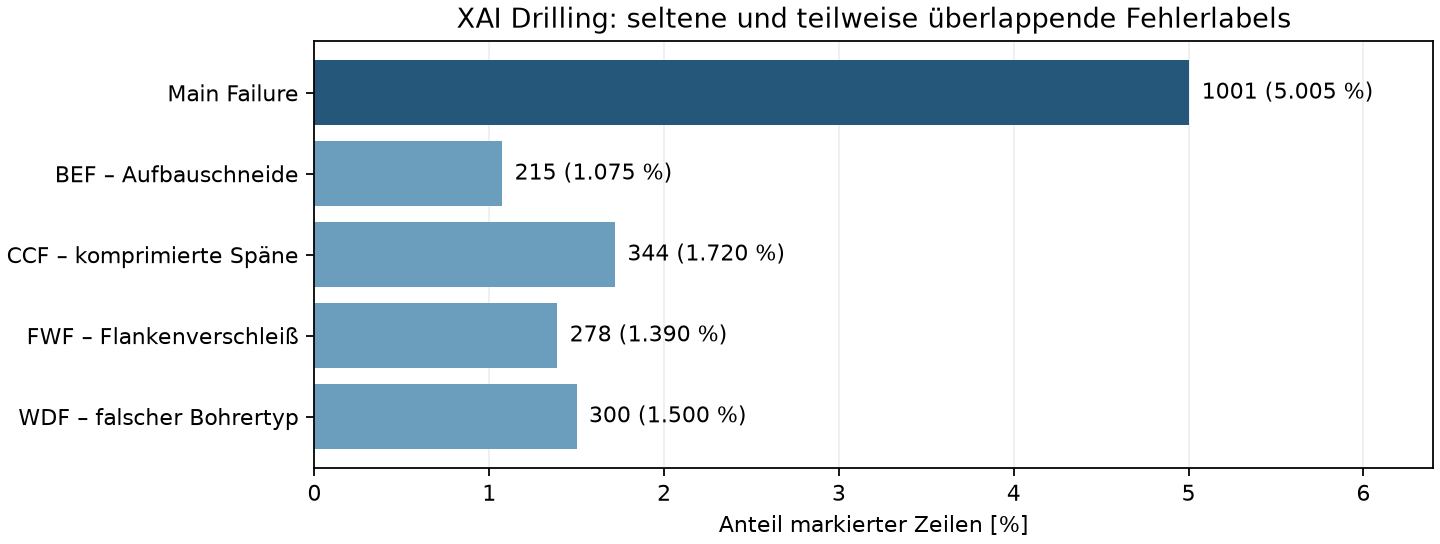

,Ziel,Markiert,Nicht markiert,Anteil [%]
0,Main Failure,1001,18999,5.005
1,BEF,215,19785,1.075
2,CCF,344,19656,1.720
3,FWF,278,19722,1.390
4,WDF,300,19700,1.500


In [2]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
labels = ["Main Failure", "BEF – Aufbauschneide", "CCF – komprimierte Späne", "FWF – Flankenverschleiß", "WDF – falscher Bohrertyp"]
fig, ax = plt.subplots(figsize=(9,3.4),layout="constrained")
ax.barh(labels,counts["Anteil [%]"],color=["#245779"]+["#6b9ebd"]*4)
for i,row in counts.iterrows():
    ax.text(row["Anteil [%]"]+.07,i,f"{int(row.Markiert)} ({row['Anteil [%]']:.3f} %)",va="center",fontsize=10)
ax.invert_yaxis();ax.set(xlabel="Anteil markierter Zeilen [%]",xlim=(0,6.4),title="XAI Drilling: seltene und teilweise überlappende Fehlerlabels")
ax.grid(axis="x",alpha=.2);ax.set_axisbelow(True)
fig.savefig(output / "01_class_counts.png",dpi=160);plt.close(fig)
display(Image(filename=str(output / "01_class_counts.png")))
display(counts)

## 4. Labelkonsistenz und Interpretation
Das Hauptflag umfasst **1.001 Fälle (5,005 %)**. Die Untergruppen enthalten BEF **215**, CCF **344**, FWF **278**, WDF **300** Markierungen. Alle positiven Ziele sind selten; selbst ein Modell ohne Fehlererkennung könnte wegen der Mehrheitsklasse hohe Accuracy erreichen. Hier werden lediglich Häufigkeiten berichtet, keine Modelle bewertet.

Main Failure stimmt **in allen 20.000 Zeilen** mit dem Untergruppen-ODER überein: **keine widersprüchlichen Labels**. Die Tabelle zählt beide Flags; Zeilen sind Main Failure, Spalten das Untergruppen-ODER. Mehrfachmarkierungen sind separat ausgewiesen.

In [3]:
display(consistency)
display(multiplicity)
print(f"Widersprüche: {len(conflicts)}; mehrere Untergruppen: {len(multiple)}")
print("IDs der ohne ID identischen Zeilen:",summary["ids_in_duplicate_groups"])

Untergruppen-ODER,0,1
Main Failure,,
0,18999,0
1,0,1001


,Anzahl Untergruppen,Zeilen
0,0,18999
1,1,887
2,2,92
3,3,22
4,4,0


Widersprüche: 0; mehrere Untergruppen: 114
IDs der ohne ID identischen Zeilen: [3152, 6070, 7196, 18565]


Von den 1.001 Fehlerzeilen haben **887 genau eine**, **92 genau zwei** und **22 genau drei** Untergruppen. Das sind **114 Mehrfachfehler**; kein Fall hat alle vier. Die Summe 1.137 der Untergruppenmarkierungen ist deshalb größer als 1.001 und kein Konsistenzfehler.

**Umgang bei künftigem Training:** Für das Hauptziel bleibt das konsistente Main-Failure-Flag erhalten. Untergruppen können als getrennte binäre Ziele oder als Mehrfachlabels behandelt werden; wir wählen nicht willkürlich den ersten Fehler und löschen keine Mehrfachfälle. Falls später echte Widersprüche auffallen, würden wir diese markieren, Herkunft/Semantik prüfen und eine begründete Zieldefinition in einer abgeleiteten Datei dokumentieren – niemals still Originalwerte überschreiben. Sämtliche Fehlerflags müssen aus den Eingaben entfernt werden, wenn sie selbst oder das daraus abgeleitete Hauptflag vorhergesagt werden sollen. Identische Beobachtungen sollten nicht unbemerkt auf TRAIN und TEST verteilt werden; das ist vor einem späteren Modellvergleich zu behandeln, nicht hier vorwegzunehmen.

## 5. Grenzen und Fazit
Die beschreibende Labelprüfung belegt interne Konsistenz, keine reale Fehlerursache oder Güte eines Vorhersagemodells. Die Daten sind synthetisch, seltene Fehler können spätere Auswertungen unsicher machen. Einheiten und Labelbedeutung stammen aus der Quelle und wurden nicht experimentell validiert. Die vollständige Beschreibung einschließlich Subgroup failures wurde bereits gelesen; eine spätere Exploration ist nicht blind gegenüber diesen Angaben.

**Offener offizieller Schritt:** Die Registrierung auf Kaggle hat der Student noch nicht vorgenommen. Der erfolgreiche öffentliche Download ersetzt diese Anforderung nicht. Alle weiteren Anforderungen von 15.1 sind für den Human Review aufbereitet; kein Modell und keine Aufgabe 15.2 bearbeitet.

**Reproduktion:** `scripts/uv.cmd run --offline --locked python scripts/build_exercise_15_1.py --check-html`. Bei fehlender CSV: `scripts/uv.cmd run --locked python scripts/download_drilling.py`. Notebook und eigenständiges HTML sind die Lesedateien; kein PDF wird verlangt. **SCIENTIFICALLY APPROVED – FORMAL REQUIREMENT PENDING.**